# Future weather files

## Introduction

`accim.data.morphing.morph_epws` makes the weather files of the climate change scenarios of a place from its present EPW file, with the **Future Weather Generator** (<https://future-weather-generator.adai.pt/>, Rodrigues et al.), a Java tool that morphs an EPW file with the projections of the global climate models of CMIP6. For each EPW file, it keeps an EPW file for each scenario (SSP1-2.6, SSP2-4.5, SSP3-7.0 and SSP5-8.5) and timeframe (2050 and 2080), named after the original one: `Seville_ssp126_2050.epw`... `Seville_ssp585_2080.epw`.

The tool is not part of accim: download its jar file from its website. This notebook was run with **FWG CMIP6 Global 5.3.0**, which needs **Java 17 or later**. We will:

1. read from the jar which tool it is, and the Java that it needs;
2. morph the weather file of Seville;
3. compare the outdoor temperature of the present and future weather files;
4. add the ACCIS to a naturally ventilated model, and simulate it with the nine weather files;
5. compare the long-term discomfort of the nine simulations (`Table(..., long_term_indicators=True)`).

## 1. Setup and Imports

The folder of this notebook has the model (`TestModel.idf`, two zones, EnergyPlus 25.1) and the weather file of Seville (`Seville.epw`). **Set `fwg_path` to the path of your jar file**: here it is that of the environment variable `ACCIM_FWG_JAR`, if it is set (as in the tests of accim).

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from accim.data.morphing import DEFAULT_GCMS, SCENARIOS, fwg_jar_info, morph_epws
from accim.data.postprocessing.main import Table
from accim.run import run_ep
from accim.sim import accis

plt.rcParams['figure.figsize'] = [14, 5]

idf_filename = 'TestModel.idf'
epw_filename = 'Seville.epw'
fwg_path = os.environ.get('ACCIM_FWG_JAR', 'C:/FWG/FutureWeatherGenerator-CMIP6-Global-v5.3.0.jar')
for filename in (idf_filename, epw_filename):
    print(f"{filename}: {'found' if os.path.exists(filename) else 'NOT FOUND'}")
print(f"The jar file of the tool: {'found' if os.path.isfile(fwg_path) else 'NOT FOUND'}")

TestModel.idf: found
Seville.epw: found
The jar file of the tool: found


## 2. The Tool of the Jar

`fwg_jar_info` reads from the jar, without running it, the version of the tool, that of its engine (the FWG Engine, since the version 5 of the global tool) and the Java that its classes need. `morph_epws` checks the Java of the PATH against it before it moves any file: with an earlier one, it raises an error that says both. If a later Java is installed in another folder, put it first in the PATH before the call (`os.environ['PATH'] = folder + os.pathsep + os.environ['PATH']`).

In [2]:
fwg_jar_info(fwg_path)

{'version': '5.3.0', 'engine': '1.2.0', 'java': 17}

## 3. Morphing the Weather File

By default, `morph_epws` morphs all the EPW files of the folder, with the ensemble of 20 global climate models (`DEFAULT_GCMS`; `fwg_options_gcms` gives others, separated by commas) and Java from the command line (`engine='java'`). It takes about 7 minutes with them (40 seconds with two), and the tool prints its progress in the console where Jupyter runs. `engine='pyfwg'` runs the tool through [pyfwg](https://github.com/dsanchez-garcia/pyfwg) (`pip install "accim[weather]"`), which checks the options and takes those of the other versions of the tool (`pyfwg_arguments`); with this version, both engines give the same files.

In [3]:
print(f"{len(DEFAULT_GCMS)} global climate models: {', '.join(DEFAULT_GCMS)}")

morph_epws(fwg_path=fwg_path, epw_filepaths=[epw_filename])

epw_files = sorted(name for name in os.listdir() if name.endswith('.epw'))
for name in epw_files:
    print(name)

20 global climate models: BCC_CSM2_MR, CanESM5, CanESM5_1, CanESM5_CanOE, CAS_ESM2_0, CMCC_ESM2, CNRM_CM6_1_HR, CNRM_ESM2_1, EC_Earth3, EC_Earth3_Veg, FGOALS_g3, GISS_E2_1_G, GISS_E2_1_H, GISS_E2_2_G, IPSL_CM6A_LR, MIROC_ES2H, MIROC_ES2L, MIROC6, MRI_ESM2_0, UKESM1_0_LL
Seville.epw
Seville_ssp126_2050.epw
Seville_ssp126_2080.epw
Seville_ssp245_2050.epw
Seville_ssp245_2080.epw
Seville_ssp370_2050.epw
Seville_ssp370_2080.epw
Seville_ssp585_2050.epw
Seville_ssp585_2080.epw


## 4. The Future Weather Files

Each future EPW file has the year of its timeframe and, in its comments, the climate models and the scenario. We compare the dry bulb temperature of the nine files: its annual mean, that of the summer (June to August) and its maximum, and its monthly means.

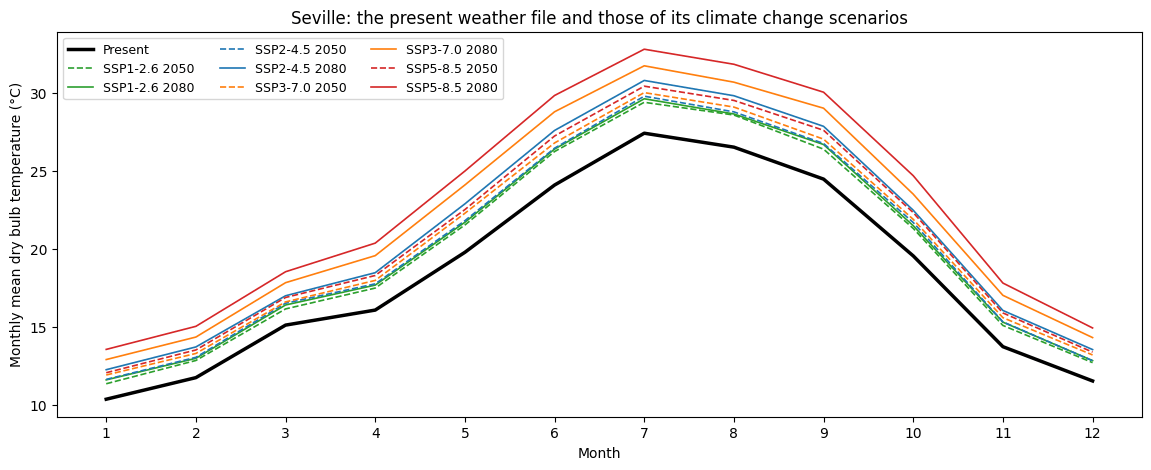

,Annual mean (°C),Summer mean (°C),Maximum (°C),"Annual mean, change (K)"
Present,18.40,26.03,43.0,0.00
SSP1-2.6 2050,19.96,28.09,45.2,1.56
SSP1-2.6 2080,20.15,28.25,45.5,1.75
SSP2-4.5 2050,20.24,28.36,45.6,1.84
SSP2-4.5 2080,21.08,29.43,46.7,2.68
SSP3-7.0 2050,20.52,28.66,45.8,2.11
SSP3-7.0 2080,22.03,30.43,47.5,3.63
SSP5-8.5 2050,20.85,29.08,46.2,2.44
SSP5-8.5 2080,22.91,31.51,48.7,4.51


In [4]:
def scenario_of(epw_name):
    # 'Seville.epw' -> 'Present'; 'Seville_ssp585_2080.epw' -> 'SSP5-8.5 2080'
    scenario = epw_name[len(epw_filename) - len('.epw'):-len('.epw')].strip('_')
    if not scenario:
        return 'Present'
    pathway, year = scenario.split('_')
    return f'SSP{pathway[3]}-{pathway[4]}.{pathway[5]} {year}'


weather = {}
for name in epw_files:
    # The data of an EPW file come after its 8 header lines: the month is its 2nd column, and the dry bulb
    # temperature the 7th
    data = pd.read_csv(name, skiprows=8, header=None, usecols=[1, 6], names=['month', 'dry bulb'])
    weather[scenario_of(name)] = data

temperatures = pd.DataFrame({
    scenario: {'Annual mean (°C)': data['dry bulb'].mean(),
               'Summer mean (°C)': data.loc[data['month'].isin([6, 7, 8]), 'dry bulb'].mean(),
               'Maximum (°C)': data['dry bulb'].max()}
    for scenario, data in weather.items()}).T
temperatures['Annual mean, change (K)'] = temperatures['Annual mean (°C)'] - temperatures.loc['Present', 'Annual mean (°C)']

colors = {'Present': 'black', 'SSP1-2.6': 'tab:green', 'SSP2-4.5': 'tab:blue', 'SSP3-7.0': 'tab:orange',
          'SSP5-8.5': 'tab:red'}
fig, ax = plt.subplots()
for scenario, data in weather.items():
    monthly = data.groupby('month')['dry bulb'].mean()
    ax.plot(monthly.index, monthly.values, color=colors[scenario.split()[0]], label=scenario,
            linestyle='--' if scenario.endswith('2050') else '-', linewidth=2.5 if scenario == 'Present' else 1.2)
ax.set_xticks(range(1, 13))
ax.set_xlabel('Month')
ax.set_ylabel('Monthly mean dry bulb temperature (°C)')
ax.set_title('Seville: the present weather file and those of its climate change scenarios')
ax.legend(ncol=3, fontsize=9)
plt.show()

temperatures.round(2)

## 5. Adding the ACCIS

We add the ACCIS to the model with the adaptive comfort model of EN 16798-1 (comfort standard 1), category II and comfort mode 3, **naturally ventilated** (`hvac_mode=[1]`: the windows open to cool the zones, and there is no heating or cooling), so that its long-term discomfort tells how the building itself copes with each climate.

In [5]:
accis.AddAccis(
    idfs=[idf_filename],
    script_type='vrf_mm',
    supply_air_temp_input_method='temperature difference',
    output_type='standard',
    output_frequencies=['hourly'],
    keep_existing_outputs=False,
    energyplus_version='auto',
    setpoint_type='temperature',
    comfort_standard=[1],
    category=[2],
    comfort_mode=[3],
    hvac_mode=[1],
    ventilation_control=[0],
    confirm=True,
    verbose=False,
)
output_idfs = sorted(name for name in os.listdir() if name.startswith('TestModel[') and name.endswith('.idf'))
for name in output_idfs:
    print(name)


--------------------------------------------------------
Adaptive-Comfort-Control-Implemented Model (ACCIM) v1.1.0
--------------------------------------------------------

This tool allows to apply adaptive setpoint temperatures. 
For further information, please read the documentation: 
https://accim.readthedocs.io/en/master/
For a visual understanding of the tool, please visit the following jupyter notebooks:
-    Using AddAccis() to apply adaptive setpoint temperatures
https://accim.readthedocs.io/en/master/jupyter_notebooks/addAccis/using_addAccis.html
-    Using rename_epw_files() to rename the EPWs for proper data analysis after simulation
https://accim.readthedocs.io/en/master/jupyter_notebooks/rename_epw_files/using_rename_epw_files.html
-    Using run_ep() to directly run simulations with EnergyPlus
https://accim.readthedocs.io/en/master/jupyter_notebooks/runEp/using_runEp.html
-    Using the class Table() for data analysis
https://accim.readthedocs.io/en/master/jupyter_noteb

## 6. Simulations

`run_ep` simulates the output IDF with each weather file of the folder: nine simulations of a year, four at a time (a few minutes in all). The future weather files are simulated as any other; `rename_epw_files` would rename them to `Country_City_Scenario-Year` first, the names that `Table` splits with `split_epw_names=True` (see the notebook of `rename_epw_files`).

In [6]:
run_ep(only_accim_idfs=True, confirm=True, processes=4, energyplus_version='auto')

The IDFs we are going to run are:
TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
 and the No. of IDFs is going to be 1
The EPWs we are going to run are:
Seville.epw
Seville_ssp126_2050.epw
Seville_ssp126_2080.epw
Seville_ssp245_2050.epw
Seville_ssp245_2080.epw
Seville_ssp370_2050.epw
Seville_ssp370_2080.epw
Seville_ssp585_2050.epw
Seville_ssp585_2080.epw
 and the No. of EPWs is going to be 9
Therefore, the simulations are going to be:
TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville
TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville_ssp126_2050
TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville_ssp126_2080
TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville_ssp245_2050
TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville_ssp245_2080
TestModel[CS_INT EN16798[CA_2[CM_3[H

## 7. The Long-term Discomfort

`Table(..., long_term_indicators=True)` calculates, for each simulation, the occupied hours with the operative temperature above the upper limit and below the lower limit of its comfort model (here, those of category II of EN 16798-1, the setpoints of the ACCIS without the tolerance), and their degree hours (Methods A and B of CEN/TR 16798-2), for each zone and for the building.

Input data frequency in file TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville_ssp126_2050.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville_ssp126_2080.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville_ssp245_2050.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Seville_ssp245_2080.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestModel[CS_INT EN16798[CA_2[CM_3[HM_1[VC_

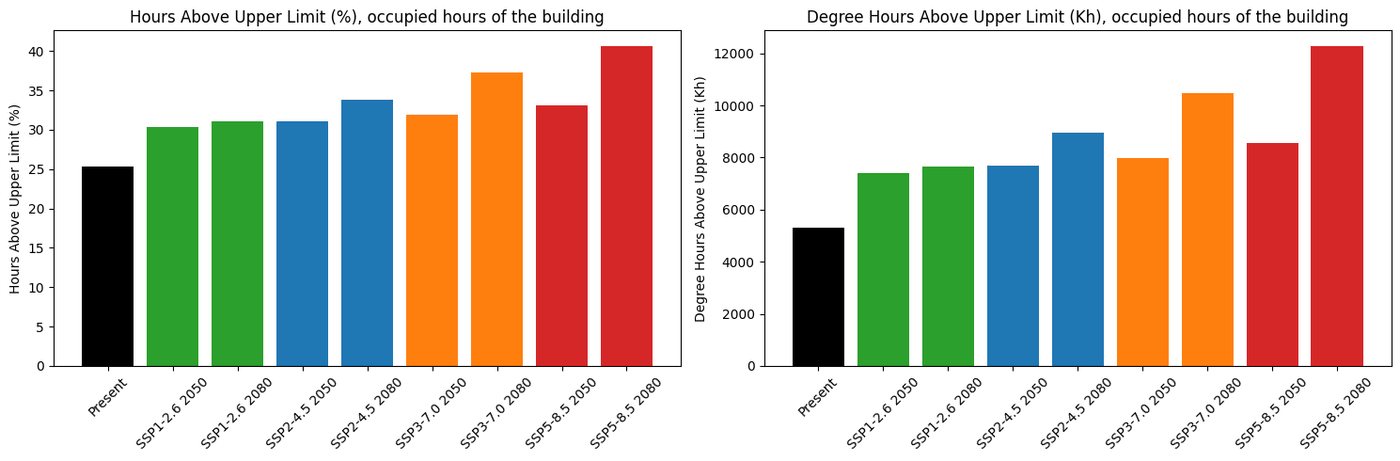

,Occupied Hours (h),Hours Above Upper Limit (h),Hours Above Upper Limit (%),Degree Hours Above Upper Limit (Kh),Hours Below Lower Limit (h)
Present,6264.0,1588.0,25.4,5314.1,1.0
SSP1-2.6 2050,6264.0,1903.0,30.4,7385.0,0.0
SSP1-2.6 2080,6264.0,1946.0,31.1,7646.9,0.0
SSP2-4.5 2050,6264.0,1947.0,31.1,7676.6,0.0
SSP2-4.5 2080,6264.0,2117.0,33.8,8958.5,0.0
SSP3-7.0 2050,6264.0,1997.0,31.9,7996.3,0.0
SSP3-7.0 2080,6264.0,2333.0,37.2,10466.4,0.0
SSP5-8.5 2050,6264.0,2074.0,33.1,8563.6,0.0
SSP5-8.5 2080,6264.0,2543.0,40.6,12266.1,0.0


In [7]:
table = Table(source_frequency='hourly', frequency='hourly', frequency_agg_func='sum', standard_outputs=True,
              level=['building'], level_agg_func=['sum'], level_excluded_zones=[], idf_path=idf_filename,
              long_term_indicators=True)

indicators = table.long_term_indicators.copy()
indicators.index = [scenario_of(f'{name}.epw') for name in indicators['EPW']]
discomfort = indicators[[
    'Building_Occupied Hours (h)', 'Building_Hours Above Upper Limit (h)', 'Building_Hours Above Upper Limit (%)',
    'Building_Degree Hours Above Upper Limit (Kh)', 'Building_Hours Below Lower Limit (h)']]
discomfort.columns = [column[len('Building_'):] for column in discomfort.columns]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bar_colors = [colors[scenario.split()[0]] for scenario in discomfort.index]
for ax, column in zip(axes, ('Hours Above Upper Limit (%)', 'Degree Hours Above Upper Limit (Kh)')):
    ax.bar(discomfort.index, discomfort[column], color=bar_colors)
    ax.set_ylabel(column)
    ax.set_title(f'{column}, occupied hours of the building')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

discomfort.round(1)

## 8. Conclusion

1. `morph_epws` makes the eight future weather files of a present one with the Future Weather Generator of the jar: it reads from the jar which tool it is, runs its command line (that of the FWG Engine, for the version 5 of the global tool) and checks first that the Java of the PATH is the one that the tool needs.
2. The future weather files are simulated as any other, and `Table(..., long_term_indicators=True)` measures the long-term discomfort of each simulation with the limits of its comfort model.
3. In this naturally ventilated model in Seville, the occupied hours above the upper limit of category II of EN 16798-1 grow from about a quarter of them with the present weather file to about 40 % with SSP5-8.5 in 2080, and their degree hours more than double; there are almost no hours below the lower limit. The adaptive limits rise with the outdoor temperature, and still the building overheats in more hours.

The results depend on the climate models of the ensemble (`fwg_options_gcms`) and on the version of the tool: note them with the results.

## 9. Cleanup

Finally, we remove the output IDF, the results of the simulations and the future weather files. **Warning:** This will permanently delete the files generated in this notebook.

In [8]:
removed = [name for name in os.listdir()
           if name.startswith('TestModel[') or any(name == f'{epw_filename[:-4]}_{scenario}.epw' for scenario in SCENARIOS)]
for name in removed:
    os.remove(name)
print(f'Removed {len(removed)} files: the output IDF, the results of its simulations and the future weather files')

Removed 171 files: the output IDF, the results of its simulations and the future weather files
